# Instamart Customer Intelligence — Parts A & B

**Project notebook**

This notebook covers the data preparation and customer intelligence stages of the capstone. I will audit the synthetic exports, clean and validate them, load the clean tables into SQLite, explore business patterns, create RFM customer segments, and evaluate a lapse-prediction model.

All records are fictional. The implementation used for the project is maintained in the `src/` modules; this notebook runs the workflow and records the analysis.

## 1. Set up the project

In [4]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-r",
    r"C:\Users\asus\OneDrive\Desktop\with_notebooks_Instamart_Customer_Intelligence_Copilot\instamart-customer-intelligence-copilot\requirements.txt"
])

0

In [2]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "matplotlib"
])

0

In [1]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "generate_data.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "generate_data.py").exists():
    raise FileNotFoundError("Open this notebook from inside the project folder.")
sys.path.insert(0, str(ROOT))
print("Project folder:", ROOT)
print("Python:", sys.version.split()[0])

Project folder: c:\Users\asus\OneDrive\Desktop\with_notebooks_Instamart_Customer_Intelligence_Copilot\instamart-customer-intelligence-copilot
Python: 3.12.10


In [3]:
import sys
print(sys.executable)

c:\Users\asus\OneDrive\Desktop\with_notebooks_Instamart_Customer_Intelligence_Copilot\.venv\Scripts\python.exe


## 2. Generate the synthetic source files

The supplied generator is kept unchanged. Running it creates reproducible raw CSV files and the policy documents used later in the project.

In [2]:
subprocess.run([sys.executable, str(ROOT / "generate_data.py")], cwd=ROOT, check=True)
raw_dir = ROOT / "data" / "raw"
print("Raw files:", sorted(path.name for path in raw_dir.glob("*.csv")))

Raw files: ['agent_scenarios.csv', 'customers.csv', 'orders.csv', 'policy_eval.csv', 'products.csv', 'tickets.csv']


## 3. Inspect and audit the raw exports

In [3]:
customers_raw = pd.read_csv(raw_dir / "customers.csv", keep_default_na=False)
products_raw = pd.read_csv(raw_dir / "products.csv", keep_default_na=False)
orders_raw = pd.read_csv(raw_dir / "orders.csv", keep_default_na=False)

raw_overview = pd.DataFrame([
    {"file": "customers.csv", "rows": len(customers_raw), "columns": len(customers_raw.columns)},
    {"file": "products.csv", "rows": len(products_raw), "columns": len(products_raw.columns)},
    {"file": "orders.csv", "rows": len(orders_raw), "columns": len(orders_raw.columns)},
])
display(raw_overview)
display(customers_raw.head())
display(products_raw.head())
display(orders_raw.head())

,file,rows,columns
0,customers.csv,1200,5
1,products.csv,40,4
2,orders.csv,13084,9


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35,MALE
1,C0002,DELHI,2024-02-17,31,MALE
2,C0003,bengaluru,2025-02-18,18,F
3,C0004,Bengaluru,2024-06-21,24,FEMALE
4,C0005,Bengaluru,2024-10-01,25,FEMALE


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245
3,P004,Sunflower Oil 1L,Grocery,155
4,P005,Sugar 1kg,Grocery,48


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes
0,ORD-108250,C0792,P004,2,2025-09-01 12:24:59,completed,0,310.0,17
1,ORD-101939,C0190,P003,1,2025-08-17 07:07:23,completed,5,232.75,21
2,ORD-108765,C0841,P033,1,2025-07-13 09:42:32,completed,10,1349.1,27
3,ORD-108861,C0852,P010,1,2025-07-04 11:23:24,completed,0,45.0,30
4,ORD-109150,C0877,P018,2,2025-05-07 15:35:01,completed,20,96.0,28


In [4]:
from src.data_pipeline import audit, clean_data, validate

audit()


customers: shape=(1200, 5)
customer_id    object
city           object
signup_date    object
age            object
gender         object
dtype: object
             missing_count  missing_pct
customer_id              0         0.00
city                     0         0.00
signup_date              0         0.00
age                     61         5.08
gender                  30         2.50

products: shape=(40, 4)
product_id      object
product_name    object
category        object
price_inr        int64
dtype: object
              missing_count  missing_pct
product_id                0          0.0
product_name              0          0.0
category                  0          0.0
price_inr                 0          0.0

orders: shape=(13084, 9)
order_id            object
customer_id         object
product_id          object
quantity             int64
order_ts            object
status              object
discount_pct         int64
order_amount        object
delivery_minutes    object
dty

### What I am checking

- Whether customer and product identifiers behave like keys.
- Whether raw files contain blank fields, duplicate orders, invalid numbers, or impossible delivery times.
- Which cleaning rules are needed before using the data for analysis.

## 4. Clean the data and validate the outputs

In [5]:
clean_tables = clean_data()
validate()

for table_name, frame in clean_tables.items():
    print(f"{table_name}: {frame.shape}")
    display(frame.head(3))

Cleaning changes: {'exact_duplicate_rows_removed': 119, 'extra_same_order_rows_removed': 656, 'amounts_reconstructed': 112, 'negative_delivery_values_set_missing': 106, 'completed_delivery_values_filled': 774}
ALL CHECKPOINTS PASSED
customers: (1200, 5)


,customer_id,city,signup_date,age,gender
0,C0001,Chennai,2024-01-13,35,male
1,C0002,Delhi,2024-02-17,31,male
2,C0003,Bengaluru,2025-02-18,18,female


products: (40, 4)


,product_id,product_name,category,price_inr
0,P001,Basmati Rice 1kg,Grocery,129
1,P002,Toor Dal 1kg,Grocery,165
2,P003,Atta 5kg,Grocery,245


orders: (12309, 9)


,order_id,customer_id,product_id,quantity,order_ts,status,discount_pct,order_amount,delivery_minutes
827,ORD-100001,C0001,P001,1,2025-09-16 08:07:21,completed,15,109.65,20
4294,ORD-100002,C0001,P008,1,2025-09-03 07:34:01,completed,40,25.20,23
9973,ORD-100003,C0001,P008,1,2025-04-08 17:08:14,completed,0,42.00,23


The cleaned CSV files and SQLite tables are now saved under `data/clean/` and `data/instamart.db`. The validation function checks the key project constraints, including unique order IDs and the completed-order revenue total.

## 5. Query the SQLite database

In [6]:
db_path = ROOT / "data" / "instamart.db"
with sqlite3.connect(db_path) as connection:
    tables_in_db = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", connection
    )

display(tables_in_db)

,name
0,customers
1,orders
2,products


In [7]:
# Run each query in sql/queries.sql separately so its result can be inspected.
query_text = (ROOT / "sql" / "queries.sql").read_text(encoding="utf-8")
queries = [q.strip() for q in query_text.split(";") if q.strip()]
print("Number of SQL statements:", len(queries))

with sqlite3.connect(db_path) as connection:
    for number, query in enumerate(queries, start=1):
        print(f"\nQuery {number}")
        try:
            display(pd.read_sql_query(query, connection).head(10))
        except Exception as exc:
            print("This statement did not return a table:", exc)

Number of SQL statements: 7

Query 1


,customer_id,spend_over_500
0,C0082,12317.70
1,C0130,9170.40
2,C0147,9141.50
3,C0167,8718.55
4,C0267,12150.25
5,C0291,12150.70
6,C0308,9872.40
7,C0332,10779.50
8,C0407,9451.75
9,C0424,8294.20



Query 2


,city,category,revenue
0,Bengaluru,Dairy,87075.05
1,Bengaluru,Electronics,233909.45
2,Bengaluru,Grocery,110915.65
3,Bengaluru,Personal Care,20193.85
4,Bengaluru,Snacks,71549.40
5,Chennai,Dairy,78301.80
6,Chennai,Electronics,195508.80
7,Chennai,Grocery,93817.45
8,Chennai,Personal Care,27675.40
9,Chennai,Snacks,68325.70



Query 3


,product_id,product_name,price_inr
0,P014,Ghee 500ml,340
1,P030,Body Lotion 400ml,350
2,P032,Sunscreen 50g,399
3,P033,Wireless Earbuds,1499
4,P034,Power Bank 10000mAh,1299
5,P035,USB-C Cable 1m,299
6,P036,Phone Charger 20W,799
7,P037,Smart Bulb,599
8,P038,Bluetooth Speaker,1999
9,P039,Phone Stand,349


... (4 outputs left out)


Query 6


,customer_id,city,total_spend,spend_rank,dense_rank,row_num
0,C0082,Bengaluru,12856.20,1,1,1
1,C0525,Bengaluru,12719.70,2,2,2
2,C0699,Bengaluru,12471.80,3,3,3
3,C0543,Bengaluru,11195.10,4,4,4
4,C1147,Bengaluru,10156.90,5,5,5
5,C0407,Bengaluru,9945.85,6,6,6
6,C0942,Bengaluru,8643.60,7,7,7
7,C1126,Bengaluru,8595.70,8,8,8
8,C0916,Bengaluru,8444.85,9,9,9
9,C0098,Bengaluru,8151.20,10,10,10



Query 7


,day,revenue,cumulative_revenue
0,2025-04-01,16876.50,16876.50
1,2025-04-02,19854.55,36731.05
2,2025-04-03,28048.35,64779.40
3,2025-04-04,14249.60,79029.00
4,2025-04-05,16031.50,95060.50
5,2025-04-06,26323.80,121384.30
6,2025-04-07,15606.90,136991.20
7,2025-04-08,17055.45,154046.65
8,2025-04-09,20403.35,174450.00
9,2025-04-10,15359.90,189809.90


## 6. Explore completed-order behaviour

In [8]:
customers = pd.read_csv(ROOT / "data" / "clean" / "customers.csv")
products = pd.read_csv(ROOT / "data" / "clean" / "products.csv")
orders = pd.read_csv(ROOT / "data" / "clean" / "orders.csv", parse_dates=["order_ts"])
completed = orders.loc[orders["status"].eq("completed")].copy()

print("Completed orders:", len(completed))
print("Completed revenue (INR):", round(completed["order_amount"].sum(), 2))
print("Mean order amount (INR):", round(completed["order_amount"].mean(), 2))
print("Median order amount (INR):", round(completed["order_amount"].median(), 2))

display(completed.groupby("status")["order_amount"].agg(["count", "sum", "mean"]))
city_summary = completed.merge(customers[["customer_id", "city"]], on="customer_id").groupby("city").agg(
    completed_orders=("order_id", "nunique"),
    revenue_inr=("order_amount", "sum"),
    mean_order_inr=("order_amount", "mean"),
).sort_values("revenue_inr", ascending=False)
display(city_summary.round(2))

Completed orders: 11110
Completed revenue (INR): 2998668.8
Mean order amount (INR): 269.91
Median order amount (INR): 135.0


,count,sum,mean
status,,,
completed,11110,2998668.8,269.907183


,completed_orders,revenue_inr,mean_order_inr
city,,,
Hyderabad,1855,528589.90,284.95
Bengaluru,1894,523643.40,276.47
Delhi,2064,502829.80,243.62
Pune,1984,500918.05,252.48
Mumbai,1613,479058.50,297.00
Chennai,1700,463629.15,272.72


In [9]:
# Revenue by city and product category, cross-checked with a pandas pivot table.
completed_products = completed.merge(products[["product_id", "category"]], on="product_id")
city_category_revenue = pd.pivot_table(
    completed_products, index="city" if "city" in completed_products.columns else "product_id",
    columns="category", values="order_amount", aggfunc="sum", fill_value=0
)
# Join customer city for a city-by-category view.
completed_with_city = completed.merge(customers[["customer_id", "city"]], on="customer_id").merge(
    products[["product_id", "category"]], on="product_id"
)
city_category_revenue = pd.pivot_table(
    completed_with_city, index="city", columns="category", values="order_amount", aggfunc="sum", fill_value=0
)
display(city_category_revenue.round(2))
print("Pivot-table grand total (INR):", round(float(city_category_revenue.to_numpy().sum()), 2))

category,Dairy,Electronics,Grocery,Personal Care,Snacks
city,,,,,
Bengaluru,87075.05,233909.45,110915.65,20193.85,71549.40
Chennai,78301.80,195508.80,93817.45,27675.40,68325.70
Delhi,117271.70,158549.10,112658.05,23471.50,90879.45
Hyderabad,83731.00,228913.10,109475.40,24800.05,81670.35
Mumbai,75209.85,214738.40,78970.15,38018.00,72122.10
Pune,90349.55,187629.25,108456.60,34275.15,80207.50


Pivot-table grand total (INR): 2998668.8


### Distribution check

I compare the mean and median because a large gap can indicate a right-skewed distribution. High-value orders are investigated rather than automatically removed.

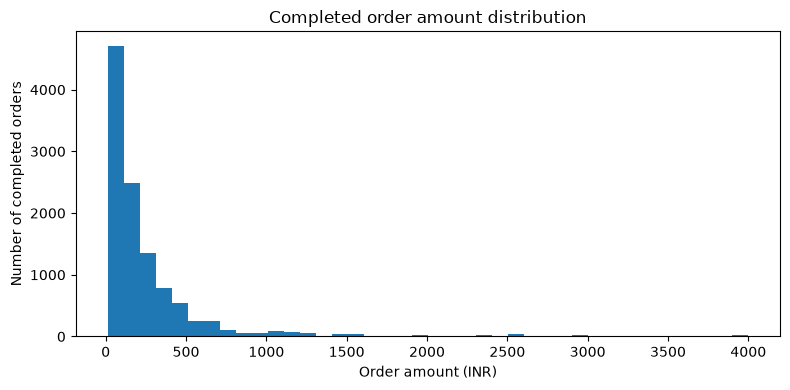

{'Q1': 64.8, 'median': 135.0, 'Q3': 297.0, 'upper_IQR_fence': 645.3, 'orders_above_upper_fence': 897}


In [10]:
plt.figure(figsize=(8, 4))
plt.hist(completed["order_amount"], bins=40)
plt.xlabel("Order amount (INR)")
plt.ylabel("Number of completed orders")
plt.title("Completed order amount distribution")
plt.tight_layout()
plt.show()

q1, q3 = completed["order_amount"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
print({
    "Q1": round(float(q1), 2), "median": round(float(completed.order_amount.median()), 2),
    "Q3": round(float(q3), 2), "upper_IQR_fence": round(float(upper_fence), 2),
    "orders_above_upper_fence": int((completed.order_amount > upper_fence).sum()),
})

## 7. Build RFM customer segments

In [11]:
from src.customer_models import rfm_and_segments, build_lapse_model

rfm, k_diagnostics, segment_profile, pca_variance = rfm_and_segments(k=4)
print("K selection diagnostics")
display(k_diagnostics.round(3))
print("Segment profile")
display(segment_profile.round(2))
print("PCA explained-variance ratios:", np.round(pca_variance, 3))
print("Saved segment file:", ROOT / "outputs" / "customer_segments.csv")

K selection diagnostics


,k,inertia,silhouette
0,2,1820.761,0.465
1,3,1268.235,0.445
2,4,743.071,0.526
3,5,617.367,0.480
4,6,503.171,0.482
5,7,408.460,0.416
6,8,366.503,0.412


Segment profile


,segment_id,size,recency,frequency,monetary
0,0,436,28.86,3.77,1057.62
1,1,138,24.12,6.77,7129.70
2,2,419,8.77,19.40,3410.02
3,3,182,109.04,2.20,685.99


PCA explained-variance ratios: [0.634 0.218]
Saved segment file: c:\Users\asus\OneDrive\Desktop\with_notebooks_Instamart_Customer_Intelligence_Copilot\instamart-customer-intelligence-copilot\outputs\customer_segments.csv


RFM summarises **Recency** (how recently a customer ordered), **Frequency** (how often they ordered), and **Monetary value** (how much they spent). Cluster IDs are labels, not a ranking; I interpret each cluster from its profile.

## 8. Train and evaluate the lapse model

In [12]:
lapse_report = build_lapse_model()
print("Cohort summary")
print({key: lapse_report[key] for key in ["cohort_rows", "lapsed", "train_rows", "test_rows"]})
print("Baseline")
print(lapse_report["baseline"])

model_rows = []
for model_name, metrics in lapse_report["models"].items():
    model_rows.append({
        "model": model_name,
        "best_parameters": metrics["best_params"],
        "CV_F1": metrics["cv_f1"],
        "precision_lapsed": metrics["precision"],
        "recall_lapsed": metrics["recall"],
        "test_F1_lapsed": metrics["f1"],
        "confusion_matrix_TN_FP_FN_TP": metrics["confusion_matrix"],
    })
display(pd.DataFrame(model_rows))
display(pd.DataFrame(lapse_report["diagnostics"].get("rf_top5_importance", [])))

Cohort summary
{'cohort_rows': 1156, 'lapsed': 443, 'train_rows': 924, 'test_rows': 232}
Baseline
{'accuracy': 0.6163793103448276, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


,model,best_parameters,CV_F1,precision_lapsed,recall_lapsed,test_F1_lapsed,confusion_matrix_TN_FP_FN_TP
0,logistic,{'model__C': 100},0.650553,0.644444,0.651685,0.648045,"[[111, 32], [31, 58]]"
1,forest,"{'model__max_depth': 8, 'model__min_samples_le...",0.686552,0.633333,0.640449,0.636872,"[[110, 33], [32, 57]]"


,feature,importance
0,num__monetary,0.280428
1,num__frequency,0.277911
2,num__recency,0.109118
3,num__avg_delivery,0.059732
4,num__cancellation_rate,0.051834


### Leakage and evaluation notes

- The lapse label is based on completed-order activity during September 2025.
- Model features are built only from information available before **2025-09-01**; September data is used only to define the label.
- Preprocessing is inside the model pipeline, so scalers and encoders are fitted on training rows only. The test set is not used to fit preprocessing or resampling.
- The customer segment label is not included as a model feature.
- The premium retention list is illustrative: its Premium flag comes from whole-window RFM and is therefore a post-hoc label, not a leakage-free evaluation.

## 9. Review the generated deliverables

In [13]:
for relative_path in [
    "data/clean/customers.csv", "data/clean/products.csv", "data/clean/orders.csv",
    "data/instamart.db", "sql/queries.sql", "outputs/customer_segments.csv",
    "outputs/lapse_model.joblib", "outputs/retention_list.csv", "outputs/model_diagnostics.json",
]:
    path = ROOT / relative_path
    print(f"{'OK' if path.exists() else 'MISSING'}  {relative_path}")

retention_path = ROOT / "outputs" / "retention_list.csv"
if retention_path.exists():
    display(pd.read_csv(retention_path).head(10))

OK  data/clean/customers.csv
OK  data/clean/products.csv
OK  data/clean/orders.csv
OK  data/instamart.db
OK  sql/queries.sql
OK  outputs/customer_segments.csv
OK  outputs/lapse_model.joblib
OK  outputs/retention_list.csv
OK  outputs/model_diagnostics.json


,customer_id,lapse_probability,actually_lapsed
0,C0862,0.510513,0
1,C0267,0.477212,0
2,C1008,0.473260,0
3,C0060,0.471746,0
4,C0802,0.471582,0
5,C0942,0.465245,0
6,C0553,0.462799,0
7,C0021,0.461252,0
8,C0133,0.460743,0
9,C0565,0.458271,1


## Part A & B — short conclusion

The raw exports require standardisation, missing-value treatment and duplicate resolution before analysis. The cleaned data is validated and available in CSV and SQLite formats. RFM provides interpretable customer groups, while the lapse model is evaluated on a held-out test set using positive-class precision, recall and F1 rather than accuracy alone. The saved outputs can now be used by the ticket-triage stage in Notebook 2.